# Final Project – Task 1: Data Exploration
**Course:** Data Literacy Foundations (2026 Fall) · **Team:** [Team name]

**Service direction:** a *scholarship finder* – a student enters school type, semester, major field and region of residence; the service filters the national scholarship catalog and returns the programs they can apply for (open now / opening soon), with amounts, deadlines and links.

**Candidate datasets compared in Task 1**

| | Dataset | Source |
|---|---|---|
| A (selected) | 한국장학재단_학자금지원정보(대학생)_20261110 – Korea Student Aid Foundation (KOSAF), student financial-aid programs | https://www.data.go.kr/data/15028252/fileData.do |
| B | 한국환경공단_전기차 충전소 위치 및 운영정보_20221027 – Korea Environment Corporation, EV charger locations | data.go.kr (Korea Environment Corporation, EV charging station location & operation info) |

This notebook loads the actual records with pandas and reproduces every table, statistic and figure in the Task 1 report. Run all cells from top to bottom (see `README.md`).

## 0. Setup and data loading

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

DATA = Path("data")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
SCHOLARSHIP_CSV = DATA / "scholarship_20261110.csv"   # original name: 한국장학재단_학자금지원정보(대학생)_20261110.csv
EV_CSV = DATA / "ev_charger_20221027.csv"             # original name: 한국환경공단_전기차_충전소_위치_및_운영정보_20221027.csv
REF_DATE = pd.Timestamp("2026-11-10")                 # version date of the scholarship file

raw = pd.read_csv(SCHOLARSHIP_CSV, encoding="cp949")  # data.go.kr files are CP949 (EUC-KR) encoded
print(f"pandas {pd.__version__}")
print(f"Scholarship file: {raw.shape[0]:,} rows x {raw.shape[1]} columns")

pandas 3.0.5
Scholarship file: 1,944 rows x 22 columns


### English column names
The original Korean headers are kept in the mapping below; the rest of the notebook uses the English names.

In [2]:
COLS = {
    "번호": "no", "운영기관명": "org_name", "상품명": "program_name", "운영기관구분": "org_type",
    "상품구분": "product_type", "학자금유형구분": "aid_type", "대학구분": "school_type",
    "학년구분": "grade_level", "학과구분": "major_field", "성적기준 상세내용": "gpa_criteria",
    "소득기준 상세내용": "income_criteria", "지원내역 상세내용": "support_detail",
    "특정자격 상세내용": "special_qualification", "지역거주여부 상세내용": "residency_criteria",
    "선발방법 상세내용": "selection_method", "선발인원 상세내용": "recipients",
    "자격제한 상세내용": "restrictions", "추천필요여부 상세내용": "recommendation",
    "제출서류 상세내용": "documents", "홈페이지 주소": "homepage",
    "모집시작일": "apply_start", "모집종료일": "apply_end",
}
df = raw.rename(columns=COLS)
pd.DataFrame({"korean_header": list(COLS.keys()), "english_name": list(COLS.values())})

,korean_header,english_name
0,번호,no
1,운영기관명,org_name
2,상품명,program_name
3,운영기관구분,org_type
4,상품구분,product_type
5,학자금유형구분,aid_type
6,대학구분,school_type
7,학년구분,grade_level
8,학과구분,major_field
9,성적기준 상세내용,gpa_criteria


## 1. Candidate B – EV charger dataset (brief profile for the comparison)

In [3]:
SIGUNGU_CSV = DATA / "sigungu_to_sido.csv"   # district -> province lookup derived from dataset B (used in Section 6)
if EV_CSV.exists():
    ev = pd.read_csv(EV_CSV, encoding="utf-8-sig", low_memory=False)
    ev_stations = ev.drop_duplicates(["주소", "충전소명"]).shape[0]
    print(f"EV file: {ev.shape[0]:,} rows (chargers) x {ev.shape[1]} columns; "
          f"{ev_stations:,} stations (unique address + station name)")
    print("Columns:", ", ".join(ev.columns))
    print("Has latitude/longitude columns:", any(c in ev.columns for c in ["위도", "경도", "위도경도"]))
    print("\nMissing values:"); print(ev.isna().sum()[lambda s: s > 0].to_string())
    print(f"\nSlow (완속) chargers: {(ev['기종(대)'] == '완속').mean():.1%}")
    print(f"Located in apartment complexes (공동주택시설): {(ev['시설구분(대)'] == '공동주택시설').mean():.1%}")
    print(f"Restricted to some users (이용자제한): {(ev['이용자제한'] == '이용자제한').mean():.1%}")

    # District (군구) -> province (시도) lookup. Names used in several provinces (중구, 남구, 고성군 ...) are dropped;
    # for the rest we keep the province that holds >= 90% of the rows.
    pairs = ev.dropna(subset=["군구"]).groupby(["군구", "시도"]).size().rename("rows").reset_index()
    pairs["share"] = pairs["rows"] / pairs.groupby("군구")["rows"].transform("sum")
    best = pairs.sort_values("share", ascending=False).drop_duplicates("군구")
    lookup = best[(best["share"] >= 0.9) & (best["군구"] != "광주시")][["군구", "시도"]]
    mismatch = pairs.merge(lookup, on="군구", suffixes=("", "_main"))
    mismatch = mismatch.loc[mismatch["시도"] != mismatch["시도_main"], "rows"].sum()
    lookup.sort_values("군구").to_csv(SIGUNGU_CSV, index=False, encoding="utf-8-sig")
    print(f"\nDistrict names: {best.shape[0]}; unambiguous kept for the lookup: {len(lookup)}")
    print(f"EV rows whose province does not match the district's usual province: {mismatch:,}")
else:
    print("EV file not found – using the saved lookup", SIGUNGU_CSV)

EV file: 190,498 rows (chargers) x 14 columns; 50,819 stations (unique address + station name)
Columns: 시도, 군구, 주소, 충전소명, 시설구분(대), 시설구분(소), 기종(대), 기종(소), 운영기관(대), 운영기관(소), 급속충전량, 충전기타입, 이용자제한, 충전기ID
Has latitude/longitude columns: False

Missing values:
군구          284
급속충전량    183369

Slow (완속) chargers: 89.2%
Located in apartment complexes (공동주택시설): 74.8%
Restricted to some users (이용자제한): 48.3%

District names: 207; unambiguous kept for the lookup: 199
EV rows whose province does not match the district's usual province: 137


## 2. Selected dataset A – profile
### 2.1 Dimensions, columns and data types

In [4]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "n_unique": df.nunique(),
    "example": df.iloc[0].astype(str).str.slice(0, 45),
})
profile

,dtype,non_null,n_unique,example
no,int64,1944,1944,1
org_name,str,1944,908,광주남구장학회
program_name,str,1944,1311,행복나눔 장학생
org_type,str,1944,5,지자체(출자출연기관)
product_type,str,1944,2,장학금
aid_type,str,1944,7,지역연고
school_type,str,1944,59,4년제(5~6년제포함)
grade_level,str,1944,99,대학2학기대학3학기대학4학기대학5학기대학6학기대학7학기대학8학기이상대학신입생
major_field,str,1944,44,공학계열교육계열사회계열예체능계열의약계열인문계열자연계열제한없음
gpa_criteria,str,1944,1004,○ 26년도 1학기 12학점 이상 취득하고 1학기 성적 평균 2.75 이상인 자


### 2.2 Representative records

In [5]:
show = ["org_name", "program_name", "org_type", "aid_type", "school_type", "support_detail", "apply_start", "apply_end"]
df[show].head(5)

,org_name,program_name,org_type,aid_type,school_type,support_detail,apply_start,apply_end
0,광주남구장학회,행복나눔 장학생,지자체(출자출연기관),지역연고,4년제(5~6년제포함),○ 1인당 100만원 (생활비 지원),2026-09-14,2026-10-02
1,광주남구장학회,일반장학생,지자체(출자출연기관),지역연고,해당없음,○ 1인당 100만원○ 등록금 지원,2026-09-14,2026-10-02
2,광주남구장학회,특별장학생,지자체(출자출연기관),지역연고,4년제(5~6년제포함),○ 1인당 100만원○ 생활비 지원 장학금으로 타 장학금 중복여부와 상관없이 신청 가능,2026-09-14,2026-10-02
3,광주남구장학회,특기장학생,지자체(출자출연기관),해당없음,4년제(5~6년제포함)전문대(2~3년제),○ 100만원,2026-09-14,2026-10-02
4,광주남구장학회,봉사선행효행장학생,지자체(출자출연기관),해당없음,4년제(5~6년제포함)전문대(2~3년제),○ 100만원,2026-09-14,2026-10-02


In [6]:
df.groupby("aid_type").sample(1, random_state=3)[show]

,org_name,program_name,org_type,aid_type,school_type,support_detail,apply_start,apply_end
530,영암군미래교육재단,대학교입학축하금지원,지자체(출자출연기관),기타,해당없음,○ 50만원,2026-04-13,2026-05-12
1801,KEC과학교육재단,장학생,기타,성적우수,4년제(5~6년제포함),○ 연간 600만원(상/하반기 2회 분할 지급)○ 장학금 지급유형은 등록금 지원이 원칙이나 학업지원비 또는 생활지원비 명목으로 지급할 수...,2025-03-24,2025-04-18
281,재단법인민들레장학회,비전장학금,기타,소득구분,4년제(5~6년제포함)일반대학원전문대(2~3년제)전문대학원,※ 기관확인필요,2026-07-16,2026-08-06
486,재단법인 부여군굿뜨래장학회,장애인장학생,지자체(출자출연기관),장애인,해당없음,○ 200만원(생활비 장학금),2026-01-30,2026-02-13
112,강진군민장학재단,다자녀분야,지자체(출자출연기관),지역연고,4년제(5~6년제포함),○ 200만원,2026-08-05,2026-08-28
1264,사단법인 광주광역시 동구 인재육성장학회,특기,지자체(출자출연기관),특기자,4년제(5~6년제포함)전문대(2~3년제),○ 50만원 ~ 200만원,2026-08-03,2026-08-31
319,(재)한국장학재단,푸른등대 산은나눔재단 기부장학금,한국장학재단,해당없음,4년제(5~6년제포함)전문대(2~3년제),○ 학기당 250만 원 지원(2개 학기 지원)※ 자세한 사항은 한국장학재단 홈페이지 참조,2026-02-25,2026-03-12


### 2.3 What one record means
One row is **one financial-aid program (상품) offered by one organization in one recruitment round** – e.g. "행복나눔 장학생" of 광주남구장학회 with its application period. According to the portal page, the information is collected and processed manually by KOSAF from programs of local governments, private foundations, universities and public bodies, and it is updated monthly.

| Field | Meaning | Suitable for analysis? |
|---|---|---|
| `org_type`, `product_type`, `aid_type` | organization type (5), scholarship vs. other aid (2), aid type (7) | Yes – clean categories |
| `school_type`, `grade_level`, `major_field` | eligible school types / semesters / major fields | Yes after parsing – several values are glued together without separators (Section 4.1) |
| `gpa_criteria`, `income_criteria`, `residency_criteria`, … | free text starting with ○ / ※ | Partly – needs text parsing; placeholders hide missing information (Section 4.2) |
| `support_detail`, `recipients` | amount and number of recipients as text | Partly – a number can be extracted for most rows |
| `apply_start`, `apply_end` | application period (YYYY-MM-DD) | Yes – all valid dates; key for "open now" |
| `homepage` | link to the program page | Mostly – a few malformed URLs |

In [7]:
for c in ["org_type", "product_type", "aid_type"]:
    print(df[c].value_counts().to_string(), "\n")
print("Unique organizations:", df["org_name"].nunique())

org_type
지자체(출자출연기관)    997
기타             833
한국장학재단          62
공공기관            42
정부              10 

product_type
장학금    1883
학자금      61 

aid_type
지역연고    771
해당없음    400
기타      372
성적우수    146
특기자     134
소득구분    102
장애인      19 

Unique organizations: 908


## 3. Missing values and duplicates

In [8]:
print("Explicit missing values (NaN) per column:", int(df.isna().sum().sum()))
print("Fully identical rows:", df.duplicated().sum())
print("Identical rows ignoring the running number:", df.drop(columns="no").duplicated().sum())
print("Repeated (org_name, program_name):", df.duplicated(["org_name", "program_name"]).sum())
print("Repeated program_name across organizations:", df.duplicated("program_name").sum())

Explicit missing values (NaN) per column: 0
Fully identical rows: 0
Identical rows ignoring the running number: 0
Repeated (org_name, program_name): 0
Repeated program_name across organizations: 633


No cell is empty – but that does **not** mean the data is complete. Missing information is written as placeholder text instead (next section).

## 4. Data-quality issues that matter for the service
### 4.1 Multi-value fields glued together without separators
Example: `school_type = "4년제(5~6년제포함)전문대(2~3년제)"` means *4-year university* **and** *2–3-year college*. We split these by matching a fixed vocabulary and check that nothing is left over.

In [9]:
VOCAB = {
    "school_type": ["4년제(5~6년제포함)", "전문대(2~3년제)", "일반대학원", "전문대학원", "특정대학", "기술대학",
                    "원격대학", "학점은행제 대학", "해외대학", "제한없음", "해당없음"],
    "grade_level": ["대학신입생", "대학2학기", "대학3학기", "대학4학기", "대학5학기", "대학6학기", "대학7학기",
                    "대학8학기이상", "석사신입생(1학기)", "석사2학기이상", "박사과정", "연령제한", "제한없음", "해당없음"],
    "major_field": ["공학계열", "교육계열", "사회계열", "예체능계열", "의약계열", "인문계열", "자연계열",
                    "특정학과", "제한없음", "해당없음"],
}

def split_tokens(text, vocab):
    found, rest = [], text
    for v in sorted(vocab, key=len, reverse=True):
        if v in rest:
            found.append(v); rest = rest.replace(v, "")
    return found, rest.strip()

for col, vocab in VOCAB.items():
    parsed = df[col].apply(lambda t: split_tokens(t, vocab))
    df[col + "_set"] = parsed.str[0].apply(set)
    leftover = (parsed.str[1] != "").sum()
    multi = (df[col + "_set"].str.len() > 1).mean()
    print(f"{col:12s}: {df[col].nunique():3d} distinct raw strings -> {len(vocab)} tokens; "
          f"rows with >1 value {multi:.1%}; unparsed leftovers {leftover}")

school_type :  59 distinct raw strings -> 11 tokens; rows with >1 value 55.3%; unparsed leftovers 0
grade_level :  99 distinct raw strings -> 14 tokens; rows with >1 value 67.7%; unparsed leftovers 0
major_field :  44 distinct raw strings -> 10 tokens; rows with >1 value 67.4%; unparsed leftovers 0


In [10]:
# How often is each school type / major field allowed?
for col in ["school_type", "major_field"]:
    counts = df[col + "_set"].explode().value_counts()
    print(f"\n{col}:"); print(counts.to_string())


school_type:
school_type_set
4년제(5~6년제포함)    1277
전문대(2~3년제)       964
해당없음             475
일반대학원            267
기술대학             208
원격대학             188
전문대학원            187
특정대학             183
학점은행제 대학         138
해외대학             125
제한없음             112

major_field:
major_field_set
공학계열     1305
자연계열     1279
예체능계열    1264
사회계열     1261
의약계열     1257
인문계열     1257
교육계열     1244
제한없음     1223
해당없음      510
특정학과      111


### 4.2 Hidden missing values in the criteria text
The detail columns never contain NaN, but they use three kinds of values:
* **"none"** – `해당없음` ("not applicable"): the program sets *no* requirement of this kind;
* **"not in data"** – `기관확인필요` ("check with the organization") or `첨부파일 또는 홈페이지 참고` ("see attachment / homepage"): the information exists but was not entered;
* **"specified"** – an actual condition in text.

In [11]:
DETAIL = ["gpa_criteria", "income_criteria", "support_detail", "special_qualification", "residency_criteria",
          "selection_method", "recipients", "restrictions", "recommendation", "documents"]

def criterion_status(text):
    t = re.sub(r"[○※\s]", "", str(text))
    if t == "해당없음":
        return "none"
    if t in ("기관확인필요", "자세한사항은첨부파일또는홈페이지참고", "홈페이지참고") or t == "00명":
        return "not in data"
    return "specified"

status = pd.DataFrame({c: df[c].map(criterion_status) for c in DETAIL})
status_table = (status.apply(lambda s: s.value_counts(normalize=True)).T.fillna(0) * 100).round(1)[
    ["specified", "none", "not in data"]]
status_table.to_csv(OUT / "table_criteria_status.csv")
status_table

,specified,none,not in data
gpa_criteria,54.6,43.7,1.7
income_criteria,32.4,66.0,1.6
support_detail,97.2,0.0,2.8
special_qualification,90.4,5.4,4.2
residency_criteria,62.3,36.9,0.8
selection_method,64.5,0.7,34.8
recipients,73.9,0.5,25.6
restrictions,82.5,2.2,15.3
recommendation,41.1,55.7,3.2
documents,97.9,0.1,2.1


In [12]:
print("'○ 00명' (placeholder recipient count):", (df["recipients"].str.strip() == "○ 00명").sum())
print("Programs where selection_method is not in the data:", (status["selection_method"] == "not in data").sum())

'○ 00명' (placeholder recipient count): 155
Programs where selection_method is not in the data: 677


**Effect on the service.** If "not in data" were treated as "no requirement", the site would tell students they qualify when the condition is simply unknown. **Plan:** show three states in the UI – *no requirement*, *requirement (text shown)*, *check with the organization* – and never silently drop a program.

### 4.3 Ambiguous units in the GPA criteria

In [13]:
g = df["gpa_criteria"]
gpa_scales = pd.Series({
    "4.5 scale mentioned": g.str.contains(r"4\.5").sum(),
    "4.3 scale mentioned": g.str.contains(r"4\.3").sum(),
    "percentile / 100-point": g.str.contains("백분위|100점").sum(),
    "letter grade (A/B/C)": g.str.contains(r"[ABC][0+]|[ABC]학점|[ABC]이상").sum(),
}, name="programs")
gpa_scales.to_frame()

,programs
4.5 scale mentioned,376
4.3 scale mentioned,161
percentile / 100-point,169
letter grade (A/B/C),203


GPA thresholds use at least four different scales, so a single "GPA ≥ x" filter would be wrong. **Plan:** in Task 2, convert the 4.5 / 4.3 / 100-point cases to one scale where the text allows, and keep the rest as text.

### 4.4 Inconsistent region names, amounts and links

In [14]:
same_org = df[df["org_name"] == "광주남구장학회"][["program_name", "residency_criteria"]]
same_org.assign(residency_criteria=same_org["residency_criteria"].str.slice(0, 70))

,program_name,residency_criteria
0,행복나눔 장학생,○ 공고일 기준 본인이나 그 보호자가 전남광주통합특별시 남구에 주민등록상 1년 이상 주소를 두고 있는 사람
1,일반장학생,○ 공고일 현재 신청 학생 또는 학생의 부모가 광주광역시 남구에 주민등록상 1년 이상 주소를 두고 있는 자
2,특별장학생,○ 보호자 또는 본인이 선발 공고일 현재 주민등록상 주소지가 광주광역시 남구로 1년 이상 두고 신청 요건을 갖춘 자
3,특기장학생,○ 공고일 기준 본인이나 그 보호자가 광주광역시 남구에 주민등록상 1년 이상 주소를 두고 있는 사람
4,봉사선행효행장학생,○ 공고일 기준 본인이나 그 보호자가 광주광역시 남구에 주민등록상 1년 이상 주소를 두고 있는 사람


In [15]:
# Amount: first number followed by 만원 (10,000 KRW)
df["amount_manwon"] = (df["support_detail"].str.extract(r"(\d[\d,]*)\s*만\s*원")[0]
                       .str.replace(",", "").astype(float))
print(f"Amount extracted for {df['amount_manwon'].notna().mean():.1%} of programs")
print(df["amount_manwon"].describe().round(1).to_string())
print("\nExamples where no amount could be extracted:")
print(df.loc[df["amount_manwon"].isna(), "support_detail"].str.slice(0, 70).head(5).to_string())
bad_url = ~df["homepage"].str.match(r"https?://")
print(f"\nMalformed or missing homepage links: {bad_url.sum()} ({bad_url.mean():.1%})")
print(df.loc[bad_url, "homepage"].value_counts().head(6).to_string())

Amount extracted for 86.4% of programs
count    1679.0
mean      243.2
std       349.4
min         3.0
25%       100.0
50%       200.0
75%       250.0
max      9700.0

Examples where no amount could be extracted:
5                             ○ 기관확인필요
14                            ※ 기관확인필요
24    ○ 이사회에서 결정(지급년한 : 1년/생활비 명목 장학금)
25    ○ 이사회에서 결정(지급년한 : 1년/생활비 명목 장학금)
26    ○ 이사회에서 결정(지급년한 : 1년/생활비 명목 장학금)

Malformed or missing homepage links: 115 (5.9%)
homepage
해당없음                        50
www.kosaf.go.kr             34
songpaworld.co.kr            4
www.haeinjanghak.org         3
www.songamfoundation.org     1
http//www.jiheonsf.or.kr     1


* The same organization writes the same district in two ways (`전남광주통합특별시 남구` and `광주광역시 남구`), so region matching must accept both spellings.
* Amounts are written per semester, per year, as "tuition in full", or as a percentage; the extracted number is only comparable when the unit is the same. Task 2 must store the unit next to the amount.
* About 6% of links are malformed (`http//…`, `https:/…`) or `해당없음`; they must be repaired or hidden.

### 4.5 Application dates and stale rounds

In [16]:
df["apply_start"] = pd.to_datetime(df["apply_start"])
df["apply_end"] = pd.to_datetime(df["apply_end"])
print("Invalid dates:", df[["apply_start", "apply_end"]].isna().sum().sum(),
      "| end before start:", (df["apply_end"] < df["apply_start"]).sum())
print("Start dates:", df["apply_start"].min().date(), "to", df["apply_start"].max().date())
print("Application window (days):"); print((df["apply_end"] - df["apply_start"]).dt.days.describe().round(1).to_string())

def round_status(r):
    if r["apply_end"] < REF_DATE: return "closed"
    if r["apply_start"] > REF_DATE: return "upcoming"
    return "open"
df["status_at_ref"] = df.apply(round_status, axis=1)
print(f"\nStatus on {REF_DATE.date()} (file version date):")
print(df["status_at_ref"].value_counts().to_string())
print("\nRecruitment year of each record:")
print(df["apply_start"].dt.year.value_counts().sort_index().to_string())

Invalid dates: 0 | end before start: 0
Start dates: 2022-08-24 to 2026-11-16
Application window (days):
count    1944.0
mean       25.3
std        49.7
min         1.0
25%        11.0
50%        18.0
75%        27.0
max      1479.0

Status on 2026-11-10 (file version date):
status_at_ref
closed      1855
open          88
upcoming       1

Recruitment year of each record:
apply_start
2022       2
2023      22
2024      73
2025     361
2026    1486


Most records describe the *latest known* round of a program, and a few still describe rounds from 2022–2024 (they were never updated). Because programs repeat every year or semester, a closed round is still useful: the site can show "usually opens in March" instead of hiding the program. Records whose last round is more than a year old must be labelled as possibly outdated.

## 5. Descriptive statistics

In [17]:
df["window_days"] = (df["apply_end"] - df["apply_start"]).dt.days
df["n_recipients"] = pd.to_numeric(df["recipients"].str.extract(r"(\d+)\s*명")[0], errors="coerce")
df.loc[df["n_recipients"] == 0, "n_recipients"] = np.nan          # "○ 00명" placeholder
df[["amount_manwon", "n_recipients", "window_days"]].describe().round(1)

,amount_manwon,n_recipients,window_days
count,1679.0,1227.0,1944.0
mean,243.2,49.9,25.3
std,349.4,138.8,49.7
min,3.0,1.0,1.0
25%,100.0,5.0,11.0
50%,200.0,15.0,18.0
75%,250.0,38.0,27.0
max,9700.0,2000.0,1479.0


## 6. Preliminary EDA
### 6.1 Region tagging for local-residency programs
`aid_type = 지역연고` programs require the student or a parent to live in a region. We tag the province/metropolitan city (시·도) from the residency text, falling back to the organization name.

In [18]:
REGIONS = {
    "Seoul": r"서울", "Busan": r"부산", "Daegu": r"대구", "Incheon": r"인천", "Gwangju": r"광주",
    "Daejeon": r"대전", "Ulsan": r"울산", "Sejong": r"세종", "Gyeonggi": r"경기", "Gangwon": r"강원",
    "Chungbuk": r"충북|충청북도", "Chungnam": r"충남|충청남도", "Jeonbuk": r"전북|전라북도",
    "Jeonnam": r"전남|전라남도", "Gyeongbuk": r"경북|경상북도", "Gyeongnam": r"경남|경상남도", "Jeju": r"제주",
}
SIDO_EN = {"서울특별시": "Seoul", "부산광역시": "Busan", "대구광역시": "Daegu", "인천광역시": "Incheon",
           "광주광역시": "Gwangju", "대전광역시": "Daejeon", "울산광역시": "Ulsan", "세종특별자치시": "Sejong",
           "경기도": "Gyeonggi", "강원도": "Gangwon", "충청북도": "Chungbuk", "충청남도": "Chungnam",
           "전라북도": "Jeonbuk", "전라남도": "Jeonnam", "경상북도": "Gyeongbuk", "경상남도": "Gyeongnam",
           "제주특별자치도": "Jeju"}
district_lookup = pd.read_csv(SIGUNGU_CSV, encoding="utf-8-sig")
DISTRICT_TO_REGION = dict(zip(district_lookup["군구"], district_lookup["시도"].map(SIDO_EN)))

def find_regions(text):
    text = str(text)
    found = {name for name, pat in REGIONS.items() if re.search(pat, text)}
    if "Gwangju" in found and re.search(r"경기도?\s*광주", text) and not re.search(r"광주광역시|전남광주", text):
        found.discard("Gwangju")      # 경기도 광주시 is a city in Gyeonggi, not Gwangju Metropolitan City
    found |= {region for district, region in DISTRICT_TO_REGION.items() if district in text}
    return found

df["residency_status"] = status["residency_criteria"]
df["regions"] = df["residency_criteria"].apply(find_regions)
needs_region = (df["residency_status"] != "none") | (df["aid_type"] == "지역연고")
fallback = needs_region & (df["regions"].str.len() == 0)
df.loc[fallback, "regions"] = df.loc[fallback, "org_name"].apply(find_regions)   # e.g. 고창군장학재단 -> Jeonbuk

df["region_status"] = np.select(
    [df["regions"].str.len() > 0, ~needs_region], ["region-specific", "nationwide"], default="region unclear")
print(df["region_status"].value_counts().to_string())
local = df[df["aid_type"] == "지역연고"]
print(f"\nLocal-residency programs (aid_type 지역연고): {len(local):,} ({len(local) / len(df):.1%} of all); "
      f"region identified for {(local['regions'].str.len() > 0).mean():.1%}")
tagged = df[df["region_status"] == "region-specific"]
region_counts = tagged["regions"].explode().value_counts()
region_counts.rename("programs").to_frame().T

region_status
region-specific    1113
nationwide          697
region unclear      134

Local-residency programs (aid_type 지역연고): 771 (39.7% of all); region identified for 90.5%


regions,Gyeonggi,Jeonnam,Gyeongbuk,Gangwon,Gyeongnam,Chungnam,Jeonbuk,Chungbuk,Seoul,Incheon,Gwangju,Daegu,Busan,Jeju,Ulsan,Daejeon,Sejong
programs,171,158,123,99,91,88,74,69,58,47,45,40,29,22,21,15,5


### 6.2 Summary table – how aid types differ on the service-relevant fields

In [19]:
AID_EN = {"지역연고": "Local residency", "해당없음": "Not classified", "기타": "Other", "성적우수": "Academic merit",
          "특기자": "Special talent", "소득구분": "Income-based", "장애인": "Disability"}
df["aid_type_en"] = df["aid_type"].map(AID_EN)
df["gpa_status"] = status["gpa_criteria"]
df["income_status"] = status["income_criteria"]

summary = (df.groupby("aid_type_en")
    .agg(programs=("no", "size"),
         share_pct=("no", lambda s: len(s) / len(df) * 100),
         no_gpa_req_pct=("gpa_status", lambda s: (s == "none").mean() * 100),
         no_income_req_pct=("income_status", lambda s: (s == "none").mean() * 100),
         region_specific_pct=("region_status", lambda s: (s == "region-specific").mean() * 100),
         median_amount_manwon=("amount_manwon", "median"),
         open_or_upcoming=("status_at_ref", lambda s: s.isin(["open", "upcoming"]).sum()))
    .sort_values("programs", ascending=False)
    .round({"share_pct": 1, "no_gpa_req_pct": 1, "no_income_req_pct": 1, "region_specific_pct": 1,
            "median_amount_manwon": 0}))
total = pd.DataFrame({"programs": [len(df)], "share_pct": [100.0],
                      "no_gpa_req_pct": [round((df["gpa_status"] == "none").mean() * 100, 1)],
                      "no_income_req_pct": [round((df["income_status"] == "none").mean() * 100, 1)],
                      "region_specific_pct": [round((df["region_status"] == "region-specific").mean() * 100, 1)],
                      "median_amount_manwon": [df["amount_manwon"].median()],
                      "open_or_upcoming": [df["status_at_ref"].isin(["open", "upcoming"]).sum()]},
                     index=["All programs"])
summary = pd.concat([summary, total])
summary.to_csv(OUT / "table1_aid_type_summary.csv")
summary

,programs,share_pct,no_gpa_req_pct,no_income_req_pct,region_specific_pct,median_amount_manwon,open_or_upcoming
Local residency,771,39.7,38.0,66.7,90.5,200.0,23
Not classified,400,20.6,43.8,63.0,43.5,200.0,40
Other,372,19.1,52.7,72.0,18.8,200.0,12
Academic merit,146,7.5,8.2,64.4,18.5,200.0,5
Special talent,134,6.9,82.8,94.0,75.4,200.0,4
Income-based,102,5.2,47.1,17.6,32.4,200.0,5
Disability,19,1.0,73.7,57.9,52.6,150.0,0
All programs,1944,100.0,43.7,66.0,57.3,200.0,89


### 6.3 Visualization – when programs open, and where local programs are

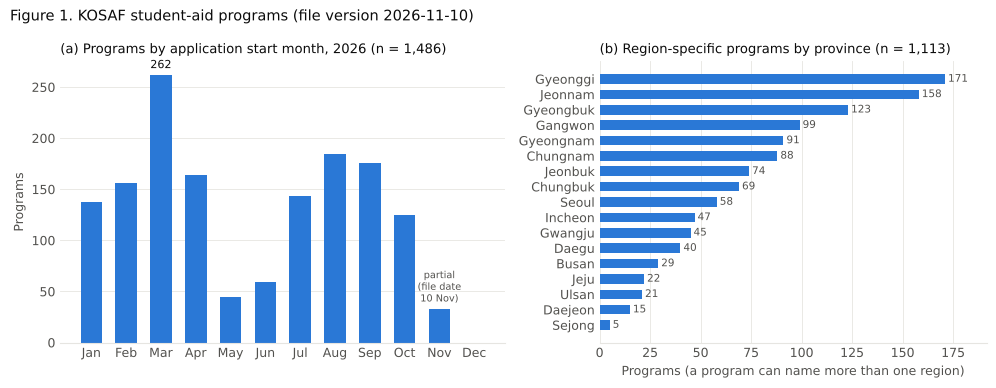

In [20]:
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})

y2026 = df[df["apply_start"].dt.year == 2026]
by_month = y2026["apply_start"].dt.month.value_counts().reindex(range(1, 13), fill_value=0)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})
ax1.bar(months, by_month.values, color=BLUE, width=0.62, zorder=2)
for i, v in enumerate(by_month.values):
    if v == by_month.max():
        ax1.text(i, v + 4, f"{v}", ha="center", va="bottom", fontsize=8, color=INK)
ax1.set_title(f"(a) Programs by application start month, 2026 (n = {len(y2026):,})", loc="left",
              fontsize=9.5, color=INK)
ax1.set_ylabel("Programs")
ax1.text(10, by_month.iloc[10] + 4, "partial\n(file date\n10 Nov)", ha="center", va="bottom", fontsize=7, color=MUTED)

rc = region_counts.sort_values()
ax2.barh(rc.index, rc.values, color=BLUE, height=0.62, zorder=2)
for y, v in enumerate(rc.values):
    ax2.text(v + 1.5, y, f"{v}", va="center", fontsize=7.5, color=MUTED)
ax2.set_title(f"(b) Region-specific programs by province (n = {len(tagged):,})", loc="left", fontsize=9.5, color=INK)
ax2.set_xlabel("Programs (a program can name more than one region)")
for ax in (ax1, ax2):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
ax1.grid(axis="y", color=GRID, linewidth=0.6, zorder=0)
ax2.grid(axis="x", color=GRID, linewidth=0.6, zorder=0)
ax2.set_xlim(0, rc.max() * 1.12)
fig.suptitle("Figure 1. KOSAF student-aid programs (file version 2026-11-10)", x=0.01, ha="left",
             fontsize=10.5, color=INK)
fig.tight_layout()
fig.savefig(OUT / "fig1_timing_and_region.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.4 Evidence-based observations (numbers computed from the records above)

In [21]:
peak = by_month.idxmax()
semester_starts = by_month.loc[[2, 3, 7, 8, 9]].sum() / by_month.sum() * 100
open_now = (df["status_at_ref"] == "open").sum(); upcoming = (df["status_at_ref"] == "upcoming").sum()
o1 = (f"Observation 1 – Programs open in waves before each semester. Of the {len(y2026):,} rounds starting in 2026, "
      f"{semester_starts:.1f}% open in Feb–Mar or Jul–Sep (peak: {months[peak - 1]}, {by_month.max()} programs). "
      f"On the file date only {open_now} programs were open and {upcoming} upcoming "
      f"({(open_now + upcoming) / len(df):.1%} of all), so the site must show *when* a program usually opens, "
      f"not only what is open today.")
top3 = region_counts.head(3)
o2 = (f"Observation 2 – Region is the strongest filter. {len(tagged):,} programs ({len(tagged) / len(df):.1%}) are tied "
      f"to a province, and local-residency programs are the largest aid type ({len(local):,}, {len(local) / len(df):.1%}). "
      f"The top three provinces ({', '.join(top3.index)}) have {', '.join(str(v) for v in top3.values)} programs, "
      f"while {region_counts.index[-1]} has {region_counts.iloc[-1]}. Where a student lives changes the result a lot.")
o3 = (f"Observation 3 – Many programs have no GPA or income condition: {(df['gpa_status'] == 'none').mean():.1%} "
      f"set no GPA requirement and {(df['income_status'] == 'none').mean():.1%} no income requirement, but "
      f"{(status['selection_method'] == 'not in data').mean():.1%} do not describe the selection method "
      f"('check with the organization').")
for o in (o1, o2, o3):
    print(o, "\n")

Observation 1 – Programs open in waves before each semester. Of the 1,486 rounds starting in 2026, 62.0% open in Feb–Mar or Jul–Sep (peak: Mar, 262 programs). On the file date only 88 programs were open and 1 upcoming (4.6% of all), so the site must show *when* a program usually opens, not only what is open today. 

Observation 2 – Region is the strongest filter. 1,113 programs (57.3%) are tied to a province, and local-residency programs are the largest aid type (771, 39.7%). The top three provinces (Gyeonggi, Jeonnam, Gyeongbuk) have 171, 158, 123 programs, while Sejong has 5. Where a student lives changes the result a lot. 

Observation 3 – Many programs have no GPA or income condition: 43.7% set no GPA requirement and 66.0% no income requirement, but 34.8% do not describe the selection method ('check with the organization'). 



## 7. Feasibility check of the core interaction (prototype, not the final service)
**User input → data operation → result.** For three example student profiles we keep programs whose parsed school type, semester and major field include the student's value (or are unrestricted), and that are nationwide or tagged with the student's province. Programs whose region could not be identified are counted separately ("check manually").

In [22]:
UNRESTRICTED = {"제한없음", "해당없음"}

def allows(allowed, value):
    return bool(allowed & ({value} | UNRESTRICTED))

def match(school, semester, major, region):
    base = df[df["school_type_set"].apply(allows, value=school)
              & df["grade_level_set"].apply(allows, value=semester)
              & df["major_field_set"].apply(allows, value=major)]
    ok = (base["region_status"] == "nationwide") | base["regions"].apply(lambda r: region in r)
    return base[ok], base[base["region_status"] == "region unclear"]

profiles = {
    "4-year univ., 3rd semester, engineering, Jeonnam": ("4년제(5~6년제포함)", "대학3학기", "공학계열", "Jeonnam"),
    "2–3-year college, freshman, humanities, Seoul":   ("전문대(2~3년제)", "대학신입생", "인문계열", "Seoul"),
    "Graduate school, master's 2nd+ sem., science, Busan": ("일반대학원", "석사2학기이상", "자연계열", "Busan"),
}
rows = []
for name, args in profiles.items():
    m, unclear = match(*args)
    rows.append({"example student": name, "matching programs": len(m),
                 "of which in own province": int((m["region_status"] == "region-specific").sum()),
                 "open on 10 Nov": int((m["status_at_ref"] == "open").sum()),
                 "region unclear (check)": len(unclear),
                 "median amount (10k KRW)": m["amount_manwon"].median()})
feasibility = pd.DataFrame(rows).set_index("example student")
feasibility.to_csv(OUT / "table2_feasibility.csv")
feasibility

,matching programs,of which in own province,open on 10 Nov,region unclear (check),median amount (10k KRW)
example student,,,,,
"4-year univ., 3rd semester, engineering, Jeonnam",597,143,22,117,200.0
"2–3-year college, freshman, humanities, Seoul",323,42,17,90,200.0
"Graduate school, master's 2nd+ sem., science, Busan",228,3,10,38,250.0


In [23]:
# What the first student would see first: open/upcoming programs sorted by deadline
m, _ = match(*profiles["4-year univ., 3rd semester, engineering, Jeonnam"])
(m[m["status_at_ref"].isin(["open", "upcoming"])].sort_values("apply_end")
   [["org_name", "program_name", "amount_manwon", "apply_start", "apply_end", "homepage"]].head(8))

,org_name,program_name,amount_manwon,apply_start,apply_end,homepage
1919,사랑의달팽이,꿈 Dream 장학금,200.0,2026-10-19,2026-11-13,https://www.soree119.com/
1591,고흥군교육발전위원회,고흥군 대학생 등록금 지원사업,200.0,2026-10-12,2026-11-13,https://www.goheung.go.kr
1133,전기공사공제조합장학회,장학생,250.0,2026-11-02,2026-11-13,http://www.ecfcsf.or.kr
1776,재단법인 숲과나눔,숲과나눔 인재양성 프로그램 장학생(공익활동가),20.0,2026-10-30,2026-11-16,https://koreashe.org
366,(재)한국장학재단,취업 후 상환 학자금대출,400.0,2026-07-01,2026-11-17,https://www.kosaf.go.kr/ko/tuition.dopg=tuition04_01_01&naviParam=HD01020201
356,(재)한국장학재단,일반 상환 학자금대출,400.0,2026-07-01,2026-11-17,https://www.kosaf.go.kr/ko/tuition.dopg=tuition04_02_01&naviParam=HD01020301
1772,재단법인 창암장학재단,창암장학생,500.0,2026-10-23,2026-11-20,https://www.changma.or.kr/
966,관정재단,학부장학생,600.0,2026-11-04,2026-11-20,https://www.ikef.or.kr/


## 8. Analytical questions for Task 2

| # | Question | Fields | Operation | Use on the website |
|---|---|---|---|---|
| Q1 | For a given student profile (school type, semester, major, region), how many programs are available and how many are open now or opening soon? | `school_type`, `grade_level`, `major_field`, `residency_criteria`, `apply_start`, `apply_end` | parse multi-value fields → filter → count by status | the core result list with "open now / opens in …" badges and a match count |
| Q2 | In which months does each kind of program usually open, and how long are application windows? | `apply_start`, `apply_end`, `aid_type`, `org_type` | month aggregation; window length (end − start) by type | "usually opens in March" hints and a calendar of upcoming rounds |
| Q3 | How do support amounts and GPA/income conditions differ by aid type and organization type? | `support_detail`, `gpa_criteria`, `income_criteria`, `aid_type`, `org_type` | text extraction (amount, unit, thresholds) → group comparison | sort/filter by amount; show "no GPA requirement" and "check with the organization" labels |

## 9. Files written by this notebook

In [24]:
for p in sorted(OUT.iterdir()):
    print(p)

outputs/fig1_timing_and_region.png
outputs/table1_aid_type_summary.csv
outputs/table2_feasibility.csv
outputs/table_criteria_status.csv
